In [1]:
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv(r"C:\Users\lokes\Desktop\ironhack\week 2\day4\lab_test\amz_uk_price_prediction_dataset.csv")

In [3]:
df=data.copy()

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Analyzing Best-Seller Trends Across Product Categories

In [5]:
freq_table = df["category"].value_counts().reset_index()
freq_table.columns = ["category", "count"]
print(freq_table)

                                   category   count
0                         Sports & Outdoors  836265
1                                    Beauty   19312
2    Handmade Clothing, Shoes & Accessories   19229
3                               Bath & Body   19092
4                            Birthday Gifts   18978
..                                      ...     ...
291                  Alexa Built-In Devices     107
292                       Motorbike Chassis     107
293                                   Plugs     107
294          Smart Home Security & Lighting     104
295                          Smart Speakers      54

[296 rows x 2 columns]


In [6]:
df["isBestSeller"].unique()

array([False,  True])

In [7]:
ct1 = pd.crosstab(df['category'], df['isBestSeller'])
ct1

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
# Add a proportion column
ct1['proportion_best_seller'] = ct1[True] / (ct1[True] + ct1[False])

# Sort descending by proportion
ct_sorted = ct1.sort_values('proportion_best_seller', ascending=False)

print(ct_sorted)



isBestSeller                      False  True  proportion_best_seller
category                                                             
Grocery                            9008   556                0.058135
Smart Home Security & Lighting       98     6                0.057692
Health & Personal Care             9017   552                0.057686
Mobile Phone Accessories            248    11                0.042471
Power & Hand Tools                 8353   306                0.035339
...                                 ...   ...                     ...
CD, Disc & Tape Players            8798     0                0.000000
General Music-Making Accessories    259     0                0.000000
Snowboard Boots                    1449     0                0.000000
Boxes & Organisers                  911     0                0.000000
eBook Readers & Accessories         246     0                0.000000

[296 rows x 3 columns]


In [9]:
top_categories = (ct1.sort_values('proportion_best_seller', ascending=False).head(10) )
print(top_categories)


isBestSeller                    False  True  proportion_best_seller
category                                                           
Grocery                          9008   556                0.058135
Smart Home Security & Lighting     98     6                0.057692
Health & Personal Care           9017   552                0.057686
Mobile Phone Accessories          248    11                0.042471
Power & Hand Tools               8353   306                0.035339
Billiard, Snooker & Pool          241     8                0.032129
Pet Supplies                     9152   285                0.030200
Home Brewing & Wine Making        239     7                0.028455
Wind Instruments                  243     7                0.028000
Mirrors                           243     7                0.028000


In [10]:
from scipy.stats import chi2_contingency

In [11]:
# Chi-square test for 'MSZoning' and 'SaleCondition'
_, chi2_pvalue, _, _  = chi2_contingency(ct1)
type(chi2_pvalue)
float(chi2_pvalue)
float(chi2_pvalue) < 0.05

True

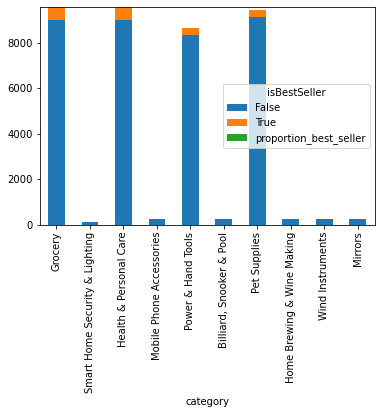

In [12]:
top_categories.plot(kind='bar', stacked=True)
plt.show()

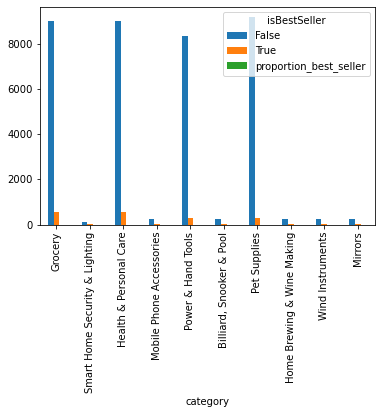

In [13]:
top_categories.plot(kind='bar', stacked=False)
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

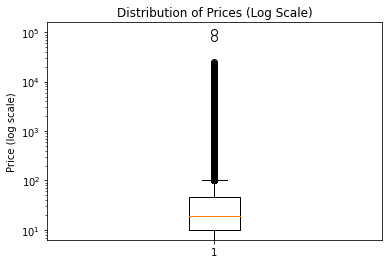

In [14]:

plt.boxplot(df['price'])
plt.yscale('log')
plt.title('Distribution of Prices (Log Scale)')
plt.ylabel('Price (log scale)')
plt.show()


In [15]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print("Before removing outliers:", df.shape[0])
print("After removing outliers:", df_no_outliers.shape[0])


Before removing outliers: 2443651
After removing outliers: 2115963


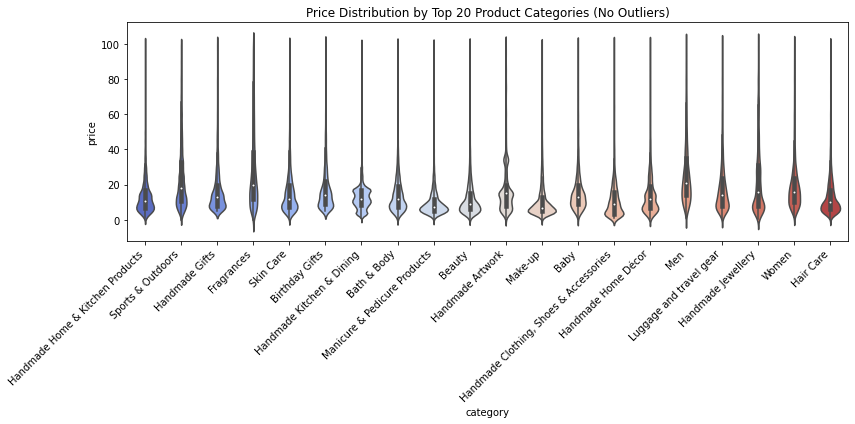

In [16]:

top20_categories = df_no_outliers['category'].value_counts().head(20).index


df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]


plt.figure(figsize=(12, 6))
sns.violinplot(data=df_top20, x='category', y='price', palette='coolwarm')
plt.xticks(rotation=45, ha='right')
plt.title('Price Distribution by Top 20 Product Categories (No Outliers)')
plt.tight_layout()
plt.show()


In [17]:
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)

print("Category with highest median price:")
print(median_prices.head(1))


Category with highest median price:
category
Desktop PCs    74.0
Name: price, dtype: float64


Text(0, 0.5, 'Number of Products')

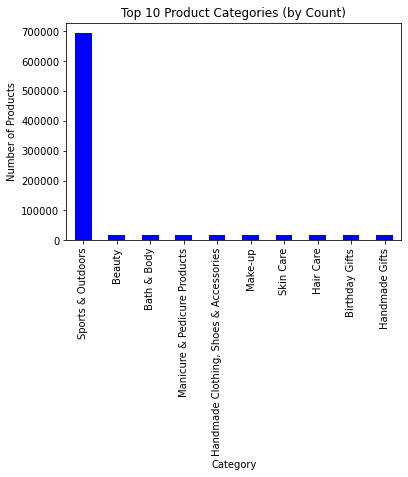

In [22]:
df_no_outliers['category'].value_counts().head(10).plot(kind='bar', color='blue')
plt.title('Top 10 Product Categories (by Count)')
plt.xlabel('Category')
plt.ylabel('Number of Products')


In [24]:
average_prices = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
print("Category with highest avearge price:")
print(average_prices.head(1))

Category with highest avearge price:
category
Motherboards    68.772432
Name: price, dtype: float64


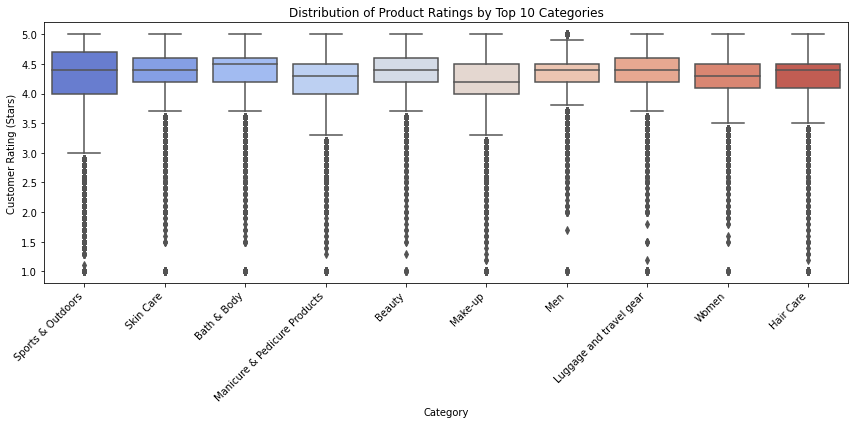

In [28]:
filtered_data = df_no_outliers[df_no_outliers["stars"] != 0]

top10_categories = filtered_data['category'].value_counts().head(10).index

df_top10 = filtered_data[filtered_data['category'].isin(top10_categories)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10, x='category', y='stars', palette='coolwarm')
plt.title('Distribution of Product Ratings by Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Customer Rating (Stars)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [29]:
median_rating = filtered_data.groupby('category')['stars'].median().sort_values(ascending=False)
print("Category with highest median_rating:")
print(median_rating.head(1))

Category with highest median_rating:
category
Made in Italy Handmade    5.0
Name: stars, dtype: float64


## Part 3: Investigating the Interplay Between Product Prices and Ratings

Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [30]:
corr = filtered_data['price'].corr(filtered_data['stars'])
print("Correlation coefficient:", corr)


Correlation coefficient: 0.006744508067157907


This means there is no strong linear correlation between price and rating — ratings don’t systematically increase or decrease with price.

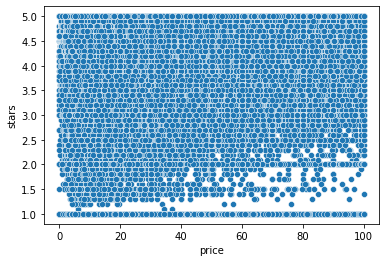

In [31]:
sns.scatterplot(data=filtered_data, x='price', y='stars')
plt.show()

In [33]:
cat = filtered_data.select_dtypes(exclude="number")
num = filtered_data.select_dtypes(include="number")

In [34]:
cat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1114343 entries, 0 to 2443650
Data columns (total 4 columns):
 #   Column        Non-Null Count    Dtype 
---  ------        --------------    ----- 
 0   asin          1114343 non-null  object
 1   title         1114343 non-null  object
 2   isBestSeller  1114343 non-null  bool  
 3   category      1114343 non-null  object
dtypes: bool(1), object(3)
memory usage: 35.1+ MB


In [35]:
num.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1114343 entries, 0 to 2443650
Data columns (total 5 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   uid                1114343 non-null  int64  
 1   stars              1114343 non-null  float64
 2   reviews            1114343 non-null  int64  
 3   price              1114343 non-null  float64
 4   boughtInLastMonth  1114343 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 51.0 MB


In [40]:
correlation_matrix = num.corr()

<AxesSubplot:>

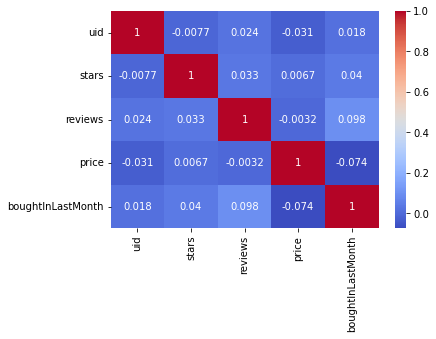

In [41]:
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

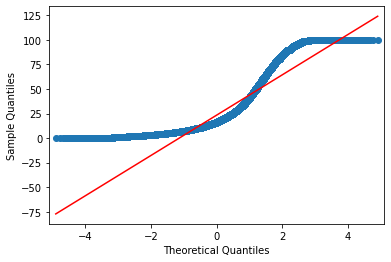

In [43]:
import statsmodels.api as sm
sm.qqplot(df_no_outliers['price'], line='s');
plt.show()